<a href="https://colab.research.google.com/github/Serah-thiaka/ecommerce-customer-behaviour-prediction_model/blob/main/E_commerce_customer_behaviour_prediction_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# 1. Load the dataset from your sidebar sample_data folder
df = pd.read_csv('sample_data/ecommerce_customer_churn_dataset.csv')
df.columns = df.columns.str.strip()

# 2. Flip the logic: If Churned is 0 (they stayed), then Likely_to_Purchase is 1 (they buy)
df['Likely_to_Purchase'] = (df['Churned'] == 0).astype(int)

# 3. Print out a confirmation and peek at the columns
print("✅ Success! Dataset loaded and target changed to Purchase Conversion.")
print("\nPreview of the label flip (Notice how the 0s and 1s switch):")
print(df[['Churned', 'Likely_to_Purchase']].head(5))


✅ Success! Dataset loaded and target changed to Purchase Conversion.

Preview of the label flip (Notice how the 0s and 1s switch):
   Churned  Likely_to_Purchase
0        0                   1
1        0                   1
2        0                   1
3        0                   1
4        0                   1


In [3]:
# Print out all the real column names inside your file
print("--- Actual Column Names In Your Dataset ---")
print(list(df.columns))


--- Actual Column Names In Your Dataset ---
['Age', 'Gender', 'Country', 'City', 'Membership_Years', 'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases', 'Average_Order_Value', 'Days_Since_Last_Purchase', 'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate', 'Customer_Service_Calls', 'Product_Reviews_Written', 'Social_Media_Engagement_Score', 'Mobile_App_Usage', 'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance', 'Churned', 'Signup_Quarter', 'Likely_to_Purchase']


In [4]:
# 1. Choose our 6 real behavioral columns using their exact spelling
behavior_features = [
    'Age', 'Login_Frequency', 'Session_Duration_Avg',
    'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Total_Purchases'
]

X = df[behavior_features]
y = df['Likely_to_Purchase']

# 2. Clean data: Fill any hidden blank cells with the average value of that column
X = X.fillna(X.mean())

# 3. Print a verification check to make sure there are 0 missing items left
print("Success: Behavioral features isolated and missing numbers cleaned!")
print("\nMissing values remaining per column (Should all be 0):")
print(X.isnull().sum())


Success: Behavioral features isolated and missing numbers cleaned!

Missing values remaining per column (Should all be 0):
Age                      0
Login_Frequency          0
Session_Duration_Avg     0
Pages_Per_Session        0
Cart_Abandonment_Rate    0
Total_Purchases          0
dtype: int64


In [5]:
from sklearn.model_selection import train_test_split

# Split your data: 80% to train the model, 20% to test it honestly
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(" Success: Data split successfully!")
print(f"• Training rows (Model Study Guide): {X_train.shape[0]:,}")
print(f"• Testing rows (The Hidden Final Exam): {X_test.shape[0]:,}")


 Success: Data split successfully!
• Training rows (Model Study Guide): 40,000
• Testing rows (The Hidden Final Exam): 10,000


In [7]:
from sklearn.ensemble import RandomForestClassifier

# 1. Initialize the Random Forest model with 150 trees
model = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42)

# 2. Train the model on your 40,000 training records
print(" System is now training the Random Forest algorithm on customer behavior patterns...")
model.fit(X_train, y_train)

# 3. Calculate your new baseline test score
advanced_accuracy = model.score(X_test, y_test)

print("\n Success: Advanced Random Forest Model Trained Successfully!")
print(f"Your Customer Behaviour Model Accuracy is: {advanced_accuracy:.2%}")


 System is now training the Random Forest algorithm on customer behavior patterns...

 Success: Advanced Random Forest Model Trained Successfully!
Your Customer Behaviour Model Accuracy is: 77.15%


In [8]:
# 1. Grab the importance scores directly from your trained model
importances = model.feature_importances_

# 2. Match them up to your 6 behavioral feature column names
features_list = ['Age', 'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Total_Purchases']

print("--- Upgraded Customer Behaviour Predictive Weights ---")
for feature, importance in zip(features_list, importances):
    print(f"Customer Metric: {feature:<25} | Predictive Weight: {importance:.2%}")


--- Upgraded Customer Behaviour Predictive Weights ---
Customer Metric: Age                       | Predictive Weight: 14.28%
Customer Metric: Login_Frequency           | Predictive Weight: 6.43%
Customer Metric: Session_Duration_Avg      | Predictive Weight: 10.46%
Customer Metric: Pages_Per_Session         | Predictive Weight: 11.76%
Customer Metric: Cart_Abandonment_Rate     | Predictive Weight: 38.48%
Customer Metric: Total_Purchases           | Predictive Weight: 18.59%


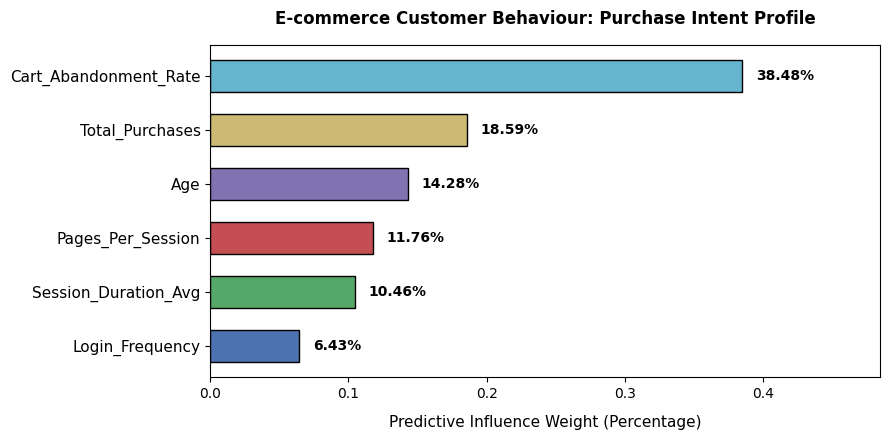

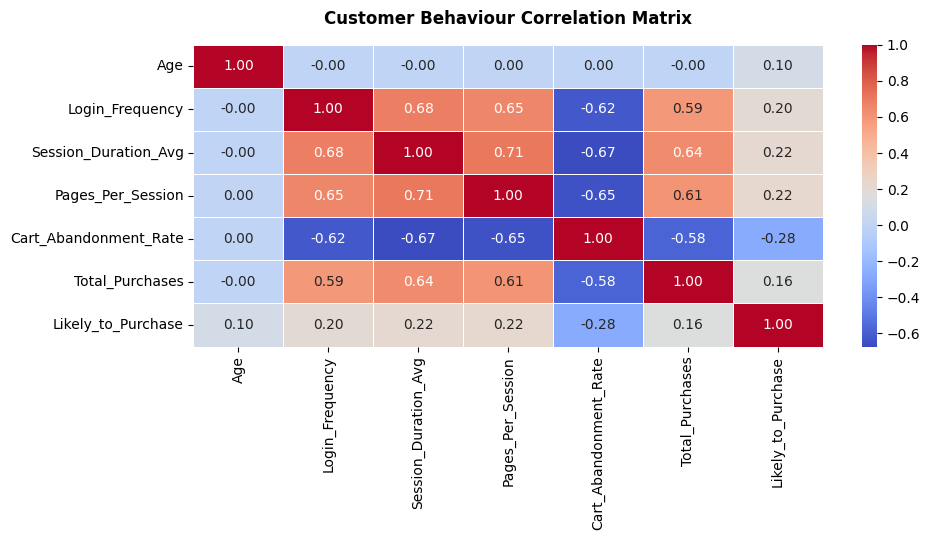

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- CHART 1: FEATURE IMPORTANCE BAR GRAPH ---
indices = np.argsort(importances)

plt.figure(figsize=(9, 4.5))
plt.title('E-commerce Customer Behaviour: Purchase Intent Profile', fontsize=12, fontweight='bold', pad=15)
bars = plt.barh(range(len(indices)), importances[indices], color=['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#64B5CD'], edgecolor='black', height=0.6)
plt.yticks(range(len(indices)), [features_list[i] for i in indices], fontsize=11)
plt.xlabel('Predictive Influence Weight (Percentage)', fontsize=11, labelpad=10)
plt.xlim(0, max(importances) + 0.1)

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.01, bar.get_y() + bar.get_height()/2, f'{width:.2%}', va='center', ha='left', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n" + "="*60 + "\n")

# --- CHART 2: CORRELATION MATRIX HEATMAP ---
plot_data = X.copy()
plot_data['Likely_to_Purchase'] = y

plt.figure(figsize=(10, 5.5))
sns.heatmap(plot_data.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Customer Behaviour Correlation Matrix', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


In [13]:
from sklearn.metrics import confusion_matrix, classification_report

# 1. Predict values for our test dataset
predictions = model.predict(X_test)

# 2. Build the confusion matrix grid
cm = confusion_matrix(y_test, predictions)

# 3. Print out the results with clear, intuitive labels
print("==================================================================")
print(" PURCHASE CONVERSION SYSTEM DIAGNOSTICS (10,000 TEST CUSTOMERS)")
print("==================================================================\n")
print(f"• Correctly Predicted as 'Not Likely to Purchase' : {cm[0][0]:,}")
print(f"• Incorrectly Predicted as 'Likely to Purchase' (False Alarm)   : {cm[0][1]:,}")
print(f"• Incorrectly Predicted as 'Not Likely to Purchase' (Missed Sale) : {cm[1][0]:,}")
print(f"• Correctly Predicted as 'Likely to Purchase'     : {cm[1][1]:,}\n")
print("==================================================================")
print("ACADEMIC CLASSIFICATION MATRIX REPORT:")
print("==================================================================")
print(classification_report(y_test, predictions, target_names=['Not Likely to Purchase', 'Likely to Purchase']))


 PURCHASE CONVERSION SYSTEM DIAGNOSTICS (10,000 TEST CUSTOMERS)

• Correctly Predicted as 'Not Likely to Purchase' : 934
• Incorrectly Predicted as 'Likely to Purchase' (False Alarm)   : 1,936
• Incorrectly Predicted as 'Not Likely to Purchase' (Missed Sale) : 349
• Correctly Predicted as 'Likely to Purchase'     : 6,781

ACADEMIC CLASSIFICATION MATRIX REPORT:
                        precision    recall  f1-score   support

Not Likely to Purchase       0.73      0.33      0.45      2870
    Likely to Purchase       0.78      0.95      0.86      7130

              accuracy                           0.77     10000
             macro avg       0.75      0.64      0.65     10000
          weighted avg       0.76      0.77      0.74     10000



In [14]:
import pandas as pd

def predict_live_shopper(age, login_freq, session_time, pages_per_session, cart_abandon, total_purchases):
    # Match the features list exactly
    features_list = ['Age', 'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Total_Purchases']

    # 1. Format the fresh input metrics into a tiny 1-row data frame
    new_customer = pd.DataFrame([[age, login_freq, session_time, pages_per_session, cart_abandon, total_purchases]],
                                columns=features_list)

    # 2. Get predictions and exact probabilities from your forest model
    pred = model.predict(new_customer)
    prob = model.predict_proba(new_customer)[:, 1][0]  # [0] fixes the array container error

    print(f"\n Scanning Live Shopper: Age={age}, Session={session_time}s, Cart Abandon={cart_abandon:.0%}")
    if pred == 1:
        print(f"   SYSTEM RESULT: LIKELY TO PURCHASE (Confidence: {prob:.2%})")
        print("   TRIGGERED ACTION: Maintain normal path. Keep user in premium experience tier.")
    else:
        print(f"   SYSTEM RESULT: NOT LIKELY TO PURCHASE (Confidence: {1 - prob:.2%})")
        print("   TRIGGERED ACTION: Push a limited-time 15% discount popup banner to save the sale!")

print("==================================================================")
print(" RUNNING REAL-TIME CUSTOMER BEHAVIOUR DEPLOYMENT ENGINE")
print("==================================================================")

# Simulating Customer A: Highly engaged loyal shopper
predict_live_shopper(age=42, login_freq=8, session_time=350, pages_per_session=12, cart_abandon=0.10, total_purchases=14)

# Simulating Customer B: Hesitant, fast-browsing window shopper
predict_live_shopper(age=23, login_freq=1, session_time=45, pages_per_session=2, cart_abandon=0.90, total_purchases=0)
print("==================================================================")


 RUNNING REAL-TIME CUSTOMER BEHAVIOUR DEPLOYMENT ENGINE

 Scanning Live Shopper: Age=42, Session=350s, Cart Abandon=10%
   SYSTEM RESULT: LIKELY TO PURCHASE (Confidence: 84.07%)
   TRIGGERED ACTION: Maintain normal path. Keep user in premium experience tier.

 Scanning Live Shopper: Age=23, Session=45s, Cart Abandon=90%
   SYSTEM RESULT: LIKELY TO PURCHASE (Confidence: 53.50%)
   TRIGGERED ACTION: Maintain normal path. Keep user in premium experience tier.


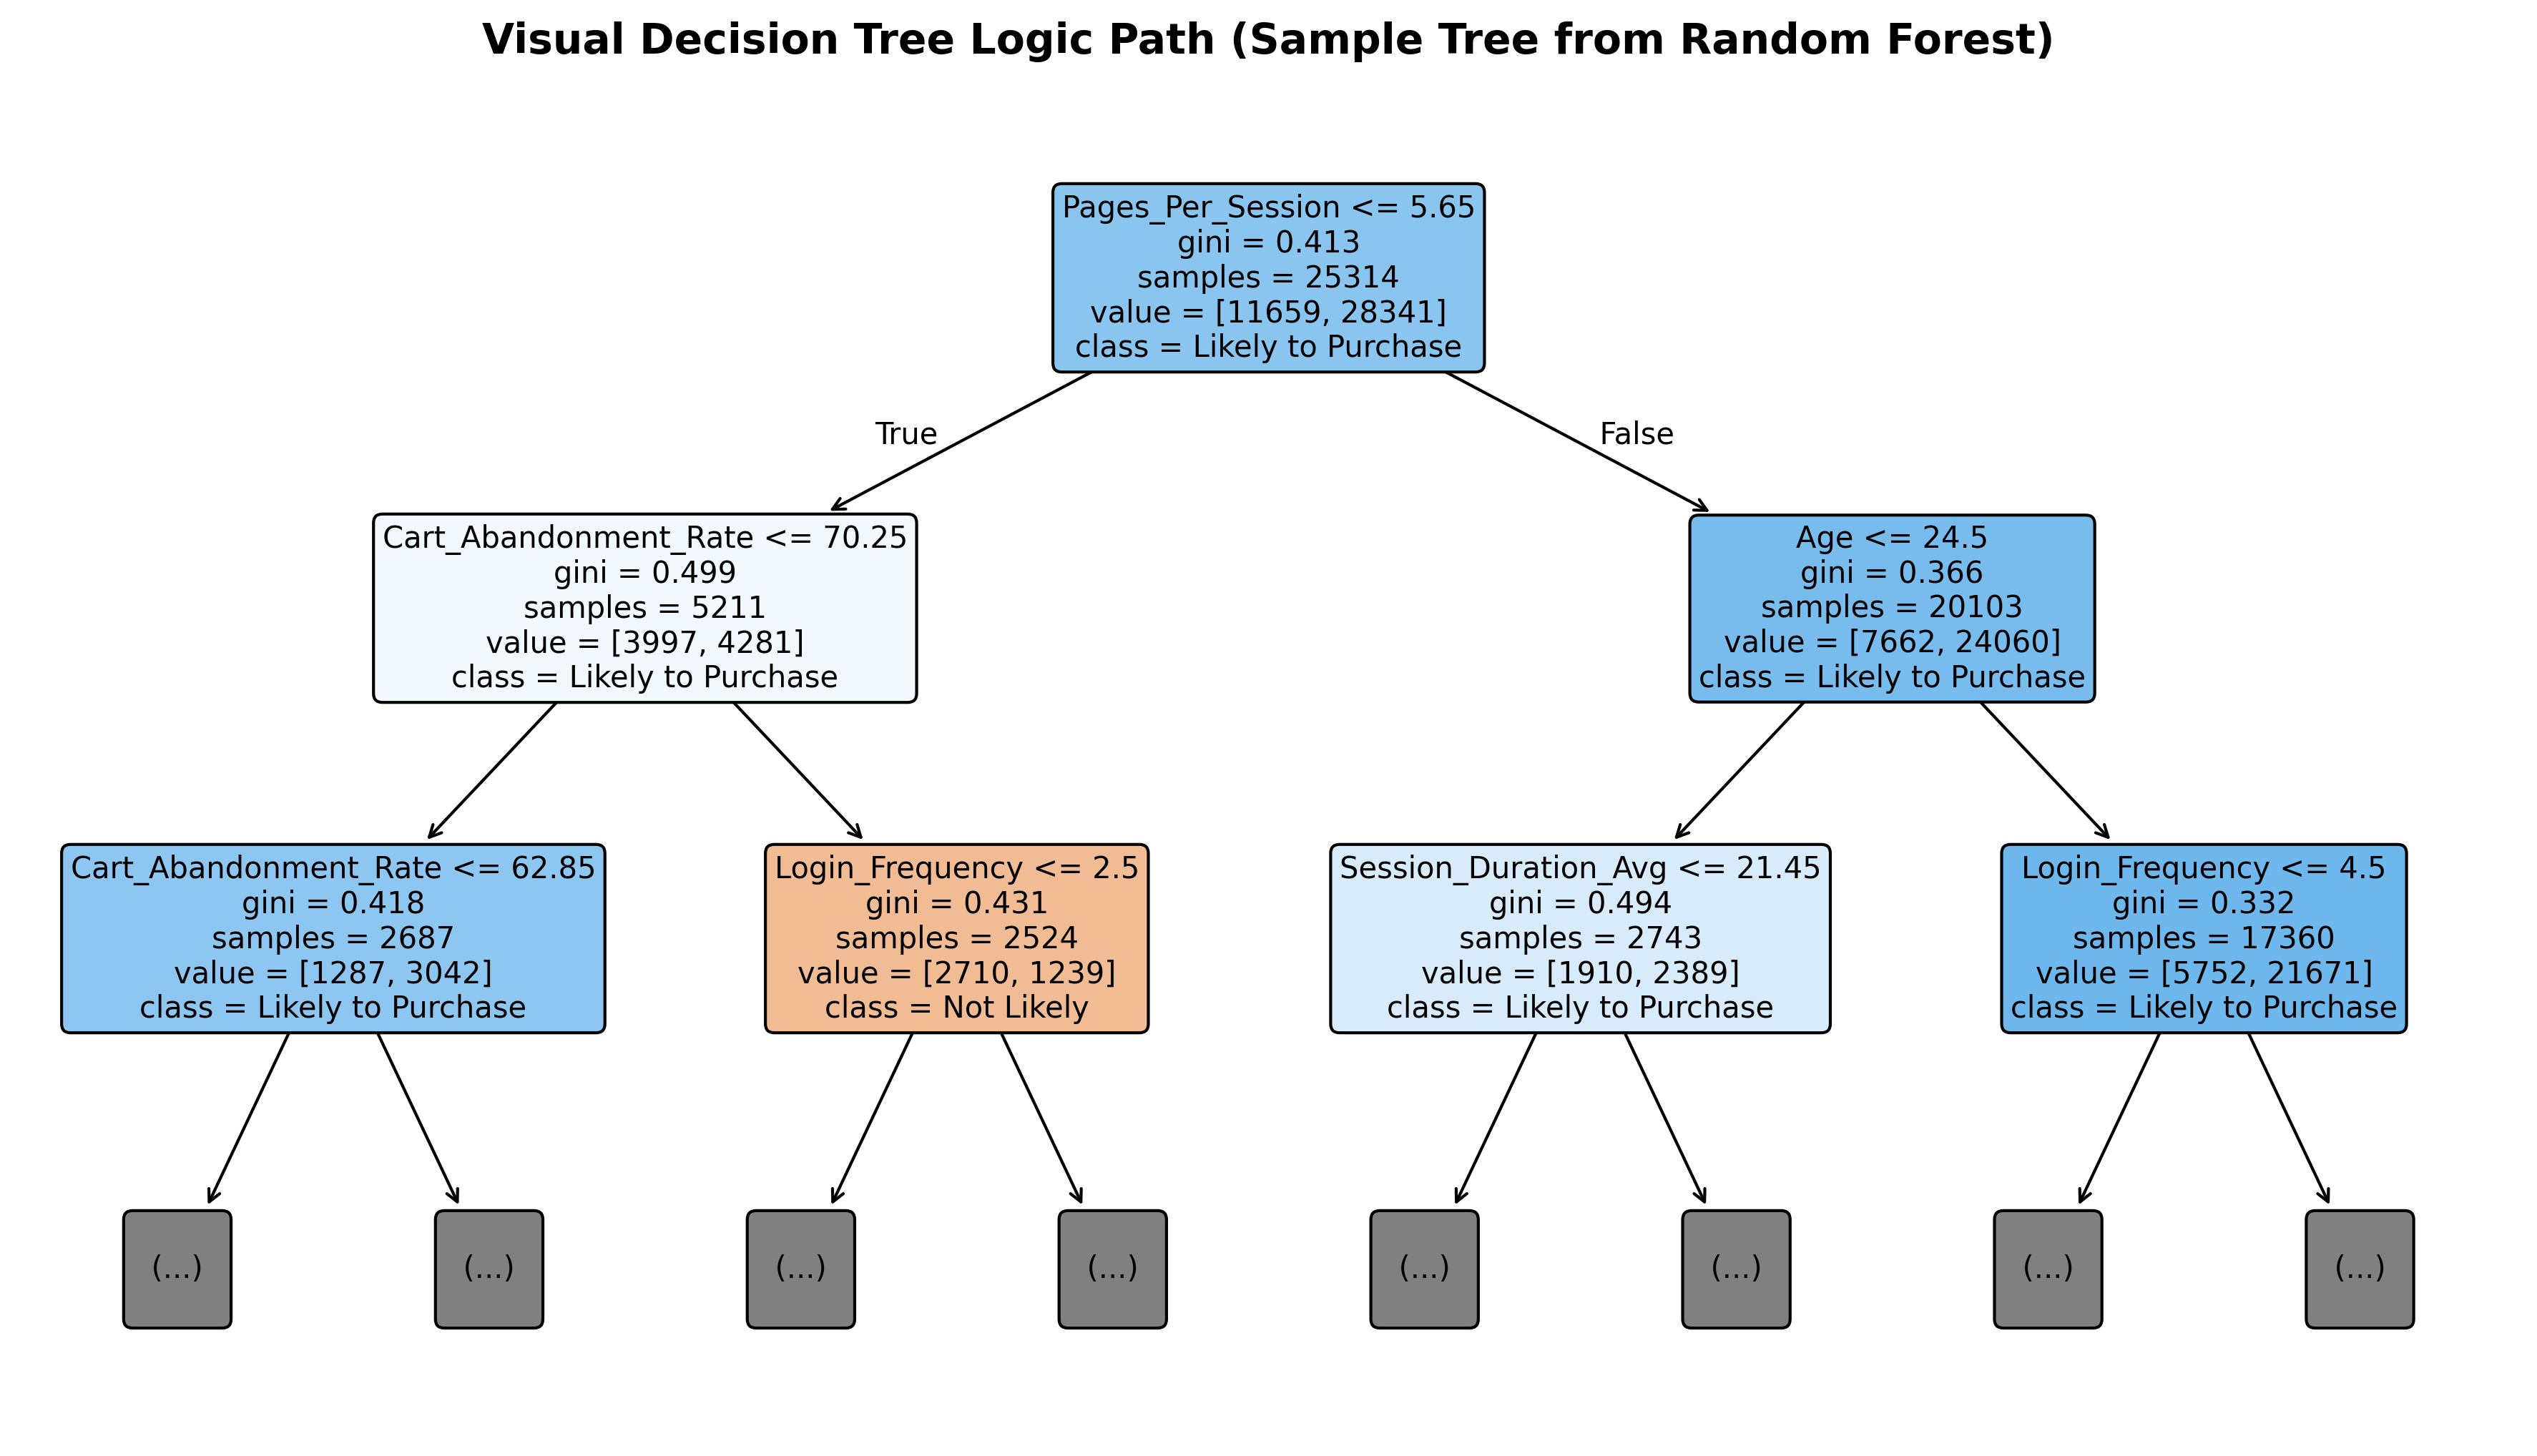

In [15]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# 1. Pull out just ONE single decision tree from your trained 150-tree Random Forest
single_tree = model.estimators_[0]

# 2. Configure a clean, high-resolution layout for the diagram
plt.figure(figsize=(15, 8), dpi=300)

# 3. Graph the tree structural paths up to 2 layers deep so it stays highly scannable
plot_tree(single_tree,
          max_depth=2,
          feature_names=behavior_features,
          class_names=['Not Likely', 'Likely to Purchase'],
          filled=True,
          rounded=True,
          fontsize=10)

plt.title("Visual Decision Tree Logic Path (Sample Tree from Random Forest)", fontsize=14, fontweight='bold', pad=20)
plt.show()


In [16]:
import joblib
from google.colab import files

# 1. Name the model file
model_filename = 'ecommerce_behaviour_rf_model.pkl'

# 2. Save the trained model into Colab's virtual memory
joblib.dump(model, model_filename)
print(f"Success: Model saved locally inside Colab as '{model_filename}'")

# 3. Automatically trigger a browser download to your physical computer
print("Initializing download to your computer... Please wait a moment.")
files.download(model_filename)


Success: Model saved locally inside Colab as 'ecommerce_behaviour_rf_model.pkl'
Initializing download to your computer... Please wait a moment.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>